In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('/content/Online Retail.csv')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
24716,538349,22845,VINTAGE CREAM CAT FOOD CONTAINER,1,10-12-2010 14:59,12.72,NaN,United Kingdom
24717,538349,22851,SET 20 NAPKINS FAIRY CAKES DESIGN,2,10-12-2010 14:59,1.66,NaN,United Kingdom
24718,538349,22855,FINE WICKER HEART,1,10-12-2010 14:59,1.24,NaN,United Kingdom
24719,538349,22855,FINE WICKER HEART,2,10-12-2010 14:59,2.51,NaN,United Kingdom


In [2]:
df.shape

(24721, 8)

In [3]:
df = df.drop_duplicates()

In [4]:
df.shape

(24369, 8)

In [5]:
df.isna().sum()

,0
InvoiceNo,0
StockCode,0
Description,111
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,8690
Country,0


<Axes: >

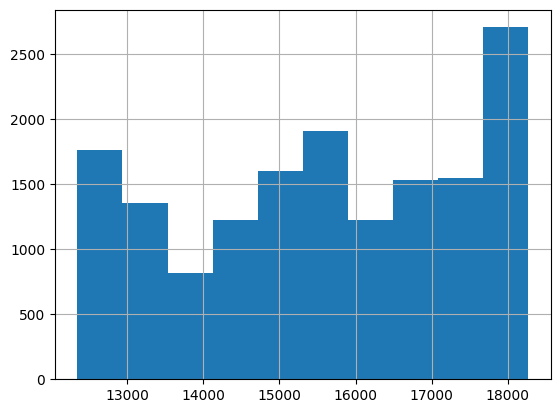

In [6]:
import matplotlib.pyplot as plt
df['CustomerID'].hist(bins=10)

In [7]:
df = df.dropna(subset=['CustomerID'])

In [8]:
#remove cancelled invoices
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [9]:
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15348 entries, 0 to 24289
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    15348 non-null  object 
 1   StockCode    15348 non-null  object 
 2   Description  15348 non-null  object 
 3   Quantity     15348 non-null  int64  
 4   InvoiceDate  15348 non-null  object 
 5   UnitPrice    15348 non-null  float64
 6   CustomerID   15348 non-null  float64
 7   Country      15348 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.1+ MB


In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['StockCode'] = le.fit_transform(df['StockCode'])
df['Country'] = le.fit_transform(df['Country'])

In [12]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [13]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,1936,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,17
1,536365,1594,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,17
2,536365,1718,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,17
3,536365,1690,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,17
4,536365,1689,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,17
...,...,...,...,...,...,...,...,...
24285,538347,992,WHITE TISSUE REAM,3,2010-10-12 14:54:00,7.95,17220.0,17
24286,538347,236,CHRISTMAS TOILET ROLL,2,2010-10-12 14:54:00,1.25,17220.0,17
24287,538347,1450,JAM MAKING SET WITH JARS,3,2010-10-12 14:54:00,4.25,17220.0,17
24288,538347,1451,JAM MAKING SET PRINTED,4,2010-10-12 14:54:00,1.45,17220.0,17


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15348 entries, 0 to 24289
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    15348 non-null  object        
 1   StockCode    15348 non-null  int64         
 2   Description  15348 non-null  object        
 3   Quantity     15348 non-null  int64         
 4   InvoiceDate  15348 non-null  datetime64[ns]
 5   UnitPrice    15348 non-null  float64       
 6   CustomerID   15348 non-null  float64       
 7   Country      15348 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 1.1+ MB


In [15]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,1936,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850.0,17,15.30
1,536365,1594,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850.0,17,20.34
2,536365,1718,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850.0,17,22.00
3,536365,1690,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850.0,17,20.34
4,536365,1689,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850.0,17,20.34


In [16]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(reference_date)

2010-10-13 14:54:00


In [17]:
rfm = df.groupby('CustomerID').agg({'InvoiceDate': lambda x: (reference_date - x.max()).days,'InvoiceNo': 'nunique','TotalPrice': 'sum'})
rfm.rename(columns={'InvoiceDate': 'Recency','InvoiceNo': 'Frequency','TotalPrice': 'Monetary'}, inplace=True)
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12347.0,92,1,711.79
12386.0,62,1,258.90
12395.0,214,1,346.10
12427.0,215,1,303.50
12429.0,31,1,1281.50


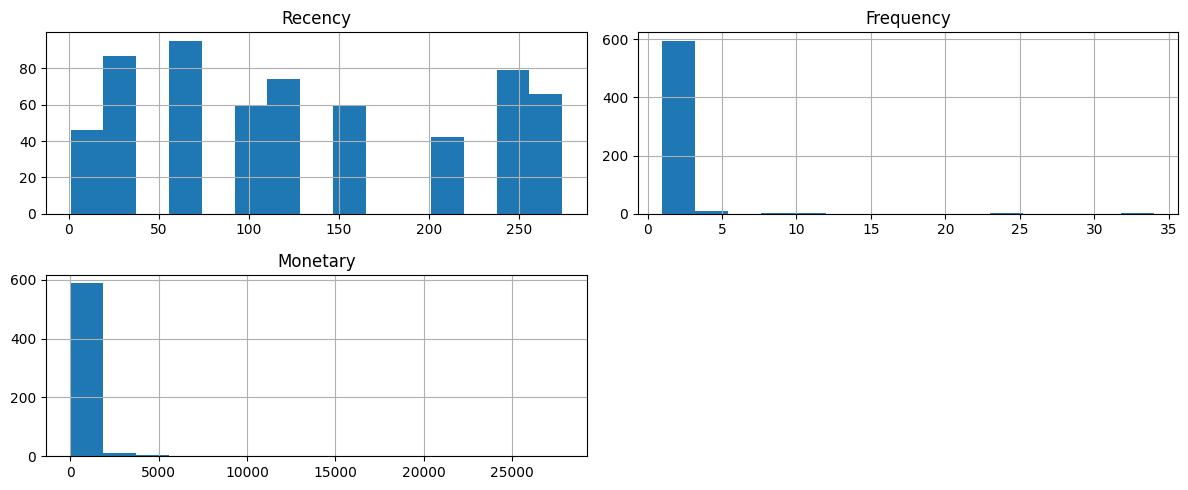

In [18]:
rfm.hist(figsize=(12, 5), bins=15)
plt.tight_layout()
plt.show()

In [19]:
rfm.describe()

,Recency,Frequency,Monetary
count,608.000000,608.000000,608.000000
mean,129.304276,1.381579,553.712549
std,89.403300,1.795782,1465.092654
min,1.000000,1.000000,15.000000
25%,61.000000,1.000000,183.637500
50%,123.000000,1.000000,307.465000
75%,215.000000,1.000000,470.472500
max,274.000000,34.000000,27834.610000


In [20]:
from sklearn.preprocessing import StandardScaler
scl = StandardScaler()
cols = rfm.columns
rfm = scl.fit_transform(rfm)
rfm = pd.DataFrame(rfm,columns=cols)

In [21]:
rfm

,Recency,Frequency,Monetary
0,-0.417602,-0.212661,0.107985
1,-0.753436,-0.212661,-0.201390
2,0.948125,-0.212661,-0.141823
3,0.959319,-0.212661,-0.170923
4,-1.100465,-0.212661,0.497161
...,...,...,...
603,-1.111660,-0.212661,-0.357755
604,-0.753436,0.344658,0.067961
605,1.261570,-0.212661,-0.078976
606,-0.753436,-0.212661,-0.121193


In [22]:
rfm.describe()

,Recency,Frequency,Monetary
count,6.080000e+02,6.080000e+02,6.080000e+02
mean,-4.382459e-17,3.213803e-17,-5.843279e-18
std,1.000823e+00,1.000823e+00,1.000823e+00
min,-1.436300e+00,-2.126612e-01,-3.680014e-01
25%,-7.646308e-01,-2.126612e-01,-2.528030e-01
50%,-7.057309e-02,-2.126612e-01,-1.682148e-01
75%,9.593190e-01,-2.126612e-01,-5.686233e-02
max,1.619793e+00,1.817886e+01,1.863593e+01


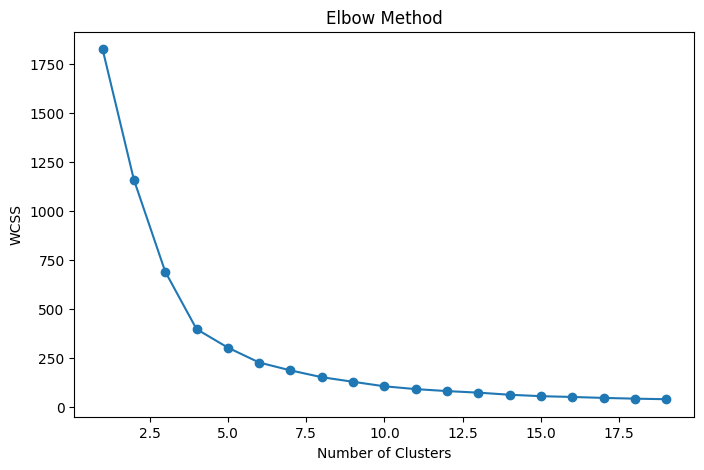

In [23]:
from sklearn.cluster import KMeans
wcss = []
for i in range(1,20):
    kmeans = KMeans(i,random_state=42,n_init = 10)
    kmeans.fit(rfm)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8, 5))
plt.plot(range(1, 20), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [24]:
kmeans = KMeans(n_clusters=4,random_state=42,n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm)
rfm.head()

,Recency,Frequency,Monetary,Cluster
0,-0.417602,-0.212661,0.107985,1
1,-0.753436,-0.212661,-0.201390,1
2,0.948125,-0.212661,-0.141823,0
3,0.959319,-0.212661,-0.170923,0
4,-1.100465,-0.212661,0.497161,1


In [25]:
rfm['Cluster'].value_counts().sort_index()

,count
Cluster,
0,246
1,358
2,2
3,2


In [26]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=1, min_samples=5)
labels = dbscan.fit_predict(rfm)
rfm["ClusterDBSCAN"] = labels

In [27]:
rfm.head()

,Recency,Frequency,Monetary,Cluster,ClusterDBSCAN
0,-0.417602,-0.212661,0.107985,1,0
1,-0.753436,-0.212661,-0.201390,1,0
2,0.948125,-0.212661,-0.141823,0,1
3,0.959319,-0.212661,-0.170923,0,1
4,-1.100465,-0.212661,0.497161,1,0


In [28]:
rfm['ClusterDBSCAN'].value_counts()

,count
ClusterDBSCAN,
0,356
1,245
-1,7


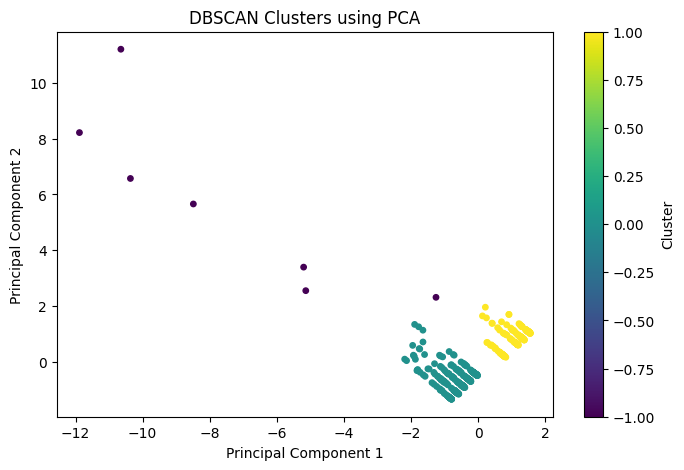

In [29]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(rfm)
plt.figure(figsize=(8, 5))
plt.scatter(pca_result[:, 0],   pca_result[:, 1],c=rfm['ClusterDBSCAN'],cmap='viridis',s=15)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clusters using PCA')
plt.colorbar(label='Cluster')
plt.show()

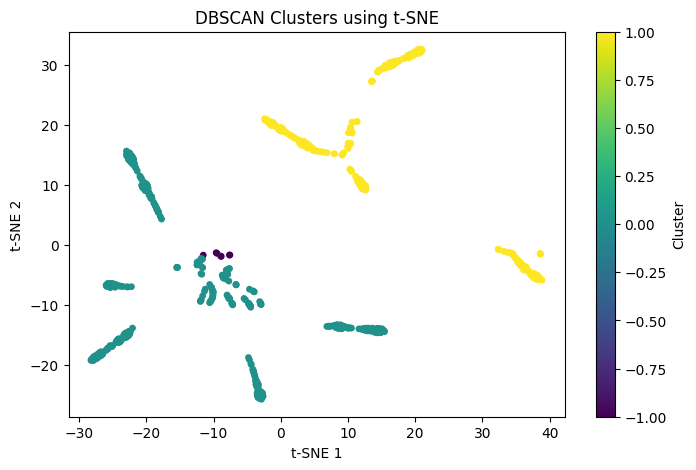

In [30]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2,random_state=42,perplexity=30,init='pca',learning_rate='auto')
tsne_result = tsne.fit_transform(rfm)
plt.figure(figsize=(8, 5))
plt.scatter(tsne_result[:, 0],tsne_result[:, 1],c=rfm['ClusterDBSCAN'],cmap='viridis',s=15)

plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.title('DBSCAN Clusters using t-SNE')
plt.colorbar(label='Cluster')
plt.show()